In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
T = nx.DiGraph()

T.add_nodes_from([0, 1, 2, 3])

T.add_edge(0, 1, length=0.5)
T.add_edge(1, 2, length=0.5)
T.add_edge(1, 3, length=0.5)

T.nodes[2]['state'] = 2
T.nodes[3]['state'] = 2

T.graph['root'] = 0

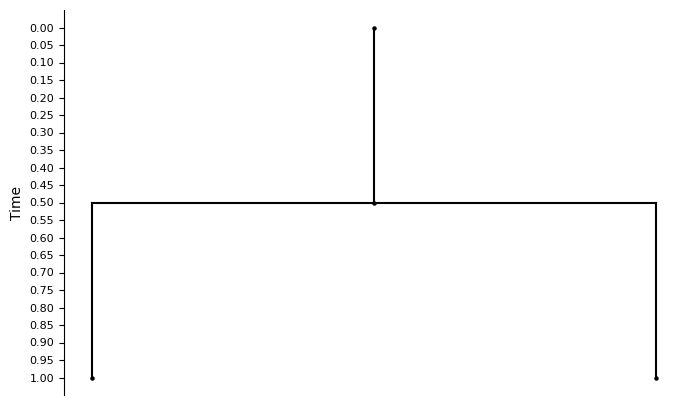

In [5]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [6]:
from likelihood import add_node_times

T = add_node_times(T, root=T.graph['root'])

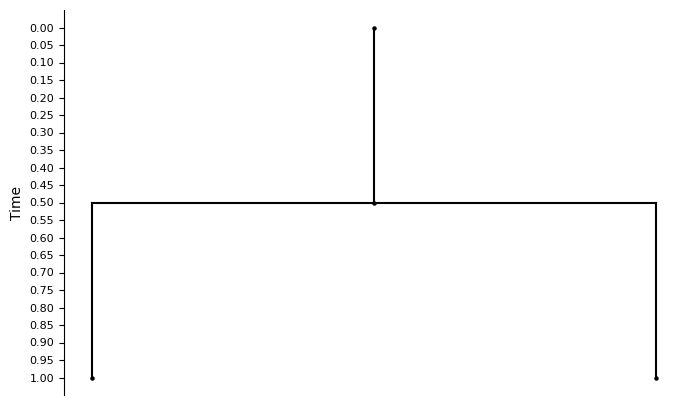

In [7]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [8]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int, {2: 2})

In [9]:
T.nodes(data=True)

NodeDataView({0: {'T': 1}, 1: {'T': 0.5}, 2: {'state': 2, 'T': 0.0}, 3: {'state': 2, 'T': 0.0}})

In [14]:
from scipy.special import logsumexp
import networkx as nx
import numpy as np
from math import log, ceil, floor

def calculate_Us(
    birth_rates: np.ndarray,
    death_rates: np.ndarray,
    sampling_rate: float,
    transition_probabilities: np.ndarray,
    one_by_delta_t: int = 1000,
    transition_filter: np.ndarray = None,
):
    num_states = len(birth_rates)
    delta_t = 1.0 / one_by_delta_t

    ####################################################################
    # Extinction probabilities U
    ####################################################################

    U = np.zeros((one_by_delta_t + 1, num_states))
    U[0, :] = 1.0 - sampling_rate

    for t in range(1, one_by_delta_t + 1):

        for s in range(num_states):

            next_transition_sum = sum(
                    transition_probabilities[s, d]
                    * delta_t
                    * U[t - 1, d]
                    for d in range(num_states)
                    if d != s
                    and (transition_filter is None or transition_filter[t, s, d])
            )

            U[t, s] = (
                (1.0
                 - (birth_rates[s]
                    + death_rates[s]
                    + transition_probabilities[s, :].sum())
                 * delta_t)
                * U[t - 1, s]
                + birth_rates[s]
                * delta_t
                * U[t - 1, s] ** 2
                + death_rates[s] * delta_t
                + next_transition_sum
            )
        
    return U


def calculate_LL_p(
    birth_rates: np.ndarray,
    death_rates: np.ndarray,
    sampling_rate: float,
    transition_probabilities: np.ndarray,
    U: np.ndarray,
    one_by_delta_t: int = 1000,
    transition_filter: np.ndarray = None,
):
    num_states = len(birth_rates)
    delta_t = 1.0 / one_by_delta_t

    LL_p = np.full((num_states, one_by_delta_t + 1, num_states), -np.inf)
    for sample_state in range(num_states):
        initial = np.full(num_states, -np.inf)
        initial[sample_state] = log(sampling_rate)
        LL_p[sample_state, 0, :] = initial
        previous = initial.copy()

        for t in range(1, one_by_delta_t + 1):

            current = np.full(num_states, -np.inf)

            A = (
                1.0
                - (birth_rates + death_rates + transition_probabilities.sum(axis=1)) * delta_t
                + 2.0
                * birth_rates
                * U[t - 1, :]
                * delta_t
            )

            for s in range(num_states):

                terms = []

                if A[s] > 0:
                    terms.append(
                        np.log(A[s]) + previous[s]
                    )

                for d in range(num_states):

                    if d == s:
                        continue

                    if transition_filter is not None and not transition_filter[t, s, d]:
                        continue

                    q = transition_probabilities[s, d]

                    if q > 0:
                        terms.append(
                            np.log(q * delta_t)
                            + previous[d]
                        )

                current[s] = logsumexp(terms)

            previous = current

            LL_p[sample_state, t, :] = current

    return LL_p






def calculate_log_likelihood_ctmc(
    T: nx.DiGraph,
    birth_rates: np.ndarray,
    death_rates: np.ndarray,
    transition_probabilities: np.ndarray,
    U: np.ndarray,
    LL_p: np.ndarray,
    one_by_delta_t: int = 1000,
    one_by_delta_t_approx: int = 50,
    transition_filter: np.ndarray = None,
):

    num_states = len(birth_rates)
    delta_t = 1.0 / one_by_delta_t

    total_rate = (
        birth_rates
        + death_rates
        + transition_probabilities.sum(axis=1)
    )

    ####################################################################
    # Postorder edge list
    ####################################################################

    postorder_edges = []


    for parent in nx.dfs_postorder_nodes(T):
        for child in T.successors(parent):
            postorder_edges.append((parent, child))

    edge_to_idx = {
        edge: idx
        for idx, edge in enumerate(postorder_edges)
    }
    num_edges = len(postorder_edges)

    # print(postorder_edges)

    ####################################################################
    # LL[e,s]
    # likelihood at parent end of edge
    ####################################################################

    def get_LL_at_time(previous, t, t_bin):
        delta_t = t - t_bin * (1.0 / one_by_delta_t)
        assert delta_t >= 0
        A = (
            1.0
            - (birth_rates + death_rates + transition_probabilities.sum(axis=1)) * delta_t
            + 2.0
            * birth_rates
            * U[t_bin, :]
            * delta_t
        )

        current = np.full(num_states, -np.inf)

        for s in range(num_states):

            terms = []

            if A[s] > 0:
                terms.append(
                    np.log(A[s]) + previous[s]
                )

            for d in range(num_states):

                if d == s:
                    continue

                if transition_filter is not None and not transition_filter[t_bin, s, d]:
                    continue

                q = transition_probabilities[s, d]

                if q > 0:
                    terms.append(
                        np.log(q * delta_t)
                        + previous[d]
                    )

            current[s] = logsumexp(terms)

        return current



    LL = np.full((num_edges, num_states), -np.inf)

    ####################################################################
    # Process edges bottom-up
    ####################################################################

    for edge_idx, (u, v) in enumerate(postorder_edges):

        parent_time = T.nodes[u]["T"]
        child_time = T.nodes[v]["T"]

        children = list(T.successors(v))

        e_t = int(floor(child_time * one_by_delta_t))
        s_t = int(floor(parent_time * one_by_delta_t))


        ###############################################################
        # likelihood at child event
        ###############################################################

        if len(children) == 0:

            child_state = T.nodes[v]["state"]
            
            LL[edge_idx] = get_LL_at_time(LL_p[child_state, s_t, :], parent_time, s_t)

            # print(f"Leaf edge {(u,v)}: child_state={child_state}, e_t={e_t}, s_t={s_t}, LL[edge_idx]={LL[edge_idx]}")

            continue


        elif len(children) == 2:

            c1, c2 = children

            LL1 = LL[edge_to_idx[(v,c1)]]
            LL2 = LL[edge_to_idx[(v,c2)]]

            if np.all(np.isneginf(LL1)):
                print("child edge not computed", (v,c1))

            if np.all(np.isneginf(LL2)):
                print("child edge not computed", (v,c2))

            initial = (
                np.log(birth_rates)
                + LL1
                + LL2
            )

        else:
            raise ValueError(
                f"Node {v} has {len(children)} children. "
                "Tree must be binary."
            )

        ###############################################################
        # discretized branch
        ###############################################################

        prev_U = np.zeros((num_states))
        dtu = child_time - (e_t) / one_by_delta_t
        assert dtu >= 0

        for s in range(num_states):

            next_transition_sum = sum(
                    transition_probabilities[s, d]
                    * dtu
                    * U[e_t, d]
                    for d in range(num_states)
                    if d != s
                    and (transition_filter is None or transition_filter[int(round(child_time * one_by_delta_t)), s, d])
            )

            prev_U[s] = (
                (1.0
                 - (birth_rates[s]
                    + death_rates[s]
                    + transition_probabilities[s, :].sum())
                 * dtu)
                * U[e_t, s]
                + birth_rates[s]
                * dtu
                * U[e_t, s] ** 2
                + death_rates[s] * dtu
                + next_transition_sum
            )


        previous = initial.copy()
        current = np.full(num_states, -np.inf)
        dt = (e_t + 1) / one_by_delta_t - child_time
        assert dt >= 0

        A = (
            1.0
            - total_rate * dt
            + 2.0
            * birth_rates
            * prev_U
            * dt
        )

        for s in range(num_states):

            terms = []

            if A[s] > 0:
                terms.append(
                    np.log(A[s]) + previous[s]
                )

            for d in range(num_states):

                if d == s:
                    continue

                if transition_filter is not None and not transition_filter[e_t + 1, s, d]:
                    continue

                q = transition_probabilities[s, d]

                if q > 0:
                    terms.append(
                        np.log(q * dt)
                        + previous[d]
                    )

            current[s] = logsumexp(terms)

        previous = current

        ###############################################################
        # propagate from child -> parent
        ###############################################################

        
        for t in range(e_t + 2, s_t):

            current = np.full(num_states, -np.inf)

            A = (
                1.0
                - total_rate * delta_t
                + 2.0
                * birth_rates
                * U[t - 1, :]
                * delta_t
            )

            for s in range(num_states):

                terms = []

                if A[s] > 0:
                    terms.append(
                        np.log(A[s]) + previous[s]
                    )

                for d in range(num_states):

                    if d == s:
                        continue

                    if transition_filter is not None and not transition_filter[t, s, d]:
                        continue

                    q = transition_probabilities[s, d]

                    if q > 0:
                        terms.append(
                            np.log(q * delta_t)
                            + previous[d]
                        )

                current[s] = logsumexp(terms)

            previous = current

        LL[edge_idx] = get_LL_at_time(previous, parent_time, s_t)

    ####################################################################
    # Root likelihood
    ####################################################################

    root = next(
        n for n in T.nodes
        if T.in_degree(n) == 0
    )

    root_children = list(T.successors(root))

    if len(root_children) != 1:
        raise ValueError(
            "Expected a dummy root with one child."
        )

    root_edge = edge_to_idx[(root, root_children[0])]

    print("LL at root edge:", root_edge, LL[root_edge])

    root_loglikelihood = LL[root_edge, 0]

    return root_loglikelihood, LL, U



transition_filter = np.full(
    (1001, 11, 11),
    True,
    dtype=bool
)


transition_probabilities = np.zeros((3, 3))

transition_probabilities[0, 1] = 1.0
transition_probabilities[1, 2] = 1.0


U = calculate_Us(
    birth_rates=np.array([5.0]*3),
    death_rates=np.array([.5]*3),
    sampling_rate=0.5,
    transition_probabilities=transition_probabilities,
    one_by_delta_t=1000,
    transition_filter=None
)

LL_p = calculate_LL_p(
    birth_rates=np.array([5.0]*3),
    death_rates=np.array([.5]*3),
    sampling_rate=0.5,
    transition_probabilities=transition_probabilities,
    U=U,
    one_by_delta_t=1000,
    transition_filter=None
)

calculate_log_likelihood_ctmc(
    T,
    birth_rates=np.array([5.0]*3),
    death_rates=np.array([.5]*3),
    transition_probabilities=transition_probabilities,
    U=U,
    LL_p=LL_p,
    one_by_delta_t=1000,
    transition_filter=None
)

LL at root edge: 2 [-6.30416698 -5.07343684 -4.3570214 ]


/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_6320/478348408.py:204: RuntimeWarning: divide by zero encountered in log
  np.log(q * delta_t)


(np.float64(-6.304166976789915),
 array([[-4.33254071, -2.86063785, -1.93017852],
        [-4.33254071, -2.86063785, -1.93017852],
        [-6.30416698, -5.07343684, -4.3570214 ]]),
 array([[0.5       , 0.5       , 0.5       ],
        [0.499     , 0.499     , 0.499     ],
        [0.49800051, 0.49800051, 0.49800051],
        ...,
        [0.10793966, 0.10793966, 0.10793966],
        [0.10790425, 0.10790425, 0.10790425],
        [0.10786899, 0.10786899, 0.10786899]], shape=(1001, 3)))

In [15]:
types = np.arange(3)

transition_maps = [
    (0, [1]),
    (1, [2]),
]


# transition_maps = [
#     (0, [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]),
#     (1, [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]),
#     (2, [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]),
#     (3, [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]),
#     (4, [1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
# ]

In [16]:
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

MAX_DEATH = 1.0
MAX_BIRTH = 500.0
MAX_TRANSITION = 200.0
COUNT = 0


def unpack_params(theta):

    k = 0

    ####################################################
    # death rates
    ####################################################

    # death = np.zeros(len(types))

    # for i in range(len(types)):
    #     death[i] = MAX_DEATH * sigmoid(theta[k])
    #     k += 1

    death = np.array([0.0] * len(types))

    ####################################################
    # birth rates
    ####################################################

    birth = np.zeros(len(types))

    for i in range(len(types)):
        birth[i] = (
            death[i]
            + (MAX_BIRTH - death[i]) * sigmoid(theta[k])
        )
        k += 1

    ####################################################
    # transition rates
    ####################################################

    Q = np.zeros((len(types), len(types)))

    type_to_idx = {
        t: i
        for i, t in enumerate(types)
    }

    for src, transition_to in transition_maps:

        i = type_to_idx[src]

        for dst in transition_to:

            j = type_to_idx[dst]

            Q[i, j] = (
                MAX_TRANSITION
                * sigmoid(theta[k])
            )

            k += 1

    return birth, death, Q


def pack_initial():

    params = []

    # # death parameters
    # params.extend([0.0] * len(types))

    # birth parameters
    params.extend([0.0] * len(types))

    # transition parameters
    for _, transition_to in transition_maps:
        params.extend([0.0] * len(transition_to))

    return np.array(params)


def neg_log_likelihood(theta, trees, sampling_rate=0.5):

    birth, death, Q = unpack_params(theta)

    U = calculate_Us(
        birth_rates=birth,
        death_rates=death,
        sampling_rate=sampling_rate,
        transition_probabilities=Q,
        one_by_delta_t=1000,
        transition_filter=None
    )

    LL_p = calculate_LL_p(
        birth_rates=birth,
        death_rates=death,
        sampling_rate=sampling_rate,
        transition_probabilities=Q,
        U=U,
        one_by_delta_t=1000,
        transition_filter=None
    )

    total_nll = 0.0

    for tree in trees:

        ll, _, _ = calculate_log_likelihood_ctmc(
            T=tree,
            birth_rates=birth,
            death_rates=death,
            transition_probabilities=Q,
            U=U,
            LL_p=LL_p,
            one_by_delta_t=1000,
            one_by_delta_t_approx=1000,
            transition_filter=None,
        )

        total_nll -= ll

    print(
        f"NLL={total_nll:.6f}",
        f"birth={birth}",
        f"death={death}",
    )

    # write_iteration(birth, death, Q, total_nll)
    # print("WROTE TO FILE")

    return total_nll



def find_params(trees, sampling_rate=0.5):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, sampling_rate),
        method="L-BFGS-B",
        options={
            "disp": True,
            "maxiter": 500,
        },
    )

    birth, death, Q = unpack_params(result.x)


    print("\nOptimization finished")
    print("Success:", result.success)
    print("Message:", result.message)
    print("Log-likelihood:", -result.fun)
    print("Birth rates:", birth)
    print("Death rates:", death)
    print("Transition rates:")
    print(Q)


    return birth, death, Q, result

import pandas as pd
import os

CSV_DIR = "../outputs/tls/params"

def write_iteration(birth, death, Q, nll):

    global COUNT

    COUNT += 1

    os.makedirs(CSV_DIR + f"/{COUNT}", exist_ok=True)

    with open(f"{CSV_DIR}/{COUNT}/birth_rates.csv", "w") as f:
        for i, x in enumerate(birth):
            f.write(f"{i},{x}\n")

    with open(f"{CSV_DIR}/{COUNT}/death_rates.csv", "w") as f:
        for i, x in enumerate(death):
            f.write(f"{i},{x}\n")

    with open(f"{CSV_DIR}/{COUNT}/transition_rates.csv", "w") as f:
        for i in range(Q.shape[0]):
            for j in range(Q.shape[1]):
                if Q[i, j] > 0:
                    f.write(f"{i},{j},{Q[i, j]}\n")
    
    with open(f"{CSV_DIR}/{COUNT}/nll.txt", "w") as f:
        f.write(f"{nll}\n")
    
    print(f"Wrote iteration {COUNT} to {CSV_DIR}/{COUNT}/")

In [17]:
find_params([T])

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_6320/2636659245.py:144: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = minimize(
/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_6320/478348408.py:204: RuntimeWarning: divide by zero encountered in log
  np.log(q * delta_t)


LL at root edge: 2 [-423.60075342 -423.60075342 -423.60075342]
NLL=423.600753 birth=[250. 250. 250.] death=[0. 0. 0.]
LL at root edge: 2 [-423.60075344 -423.60075342 -423.60075342]
NLL=423.600753 birth=[250.00000125 250.         250.        ] death=[0. 0. 0.]
LL at root edge: 2 [-423.60075344 -423.60075344 -423.60075342]
NLL=423.600753 birth=[250.         250.00000125 250.        ] death=[0. 0. 0.]
LL at root edge: 2 [-423.60075589 -423.6007559  -423.60075591]
NLL=423.600756 birth=[250.         250.         250.00000125] death=[0. 0. 0.]
LL at root edge: 2 [-423.60075342 -423.60075342 -423.60075342]
NLL=423.600753 birth=[250. 250. 250.] death=[0. 0. 0.]
LL at root edge: 2 [-423.60075342 -423.60075342 -423.60075342]
NLL=423.600753 birth=[250. 250. 250.] death=[0. 0. 0.]
LL at root edge: 2 [-211.36842786 -210.60345968 -209.83849154]
NLL=211.368428 birth=[249.36584201 249.36583047 134.47324099] death=[0. 0. 0.]
LL at root edge: 2 [-211.36842787 -210.60345968 -209.83849154]
NLL=211.368428 

(array([5.77088493e-09, 5.20276507e-09, 1.53976643e+00]),
 array([0., 0., 0.]),
 array([[ 0.        , 11.40887142,  0.        ],
        [ 0.        ,  0.        , 11.40863279],
        [ 0.        ,  0.        ,  0.        ]]),
   message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
   success: True
    status: 0
       fun: 1.5078389422643284
         x: [-2.519e+01 -2.529e+01 -5.780e+00 -2.805e+00 -2.805e+00]
       nit: 35
       jac: [ 0.000e+00  0.000e+00  6.617e-06  2.220e-08 -1.221e-06]
      nfev: 306
      njev: 51
  hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>)